## **Trabajo Práctico Grupal Final: Airbnb Price**
## Notebook N°1: Exploratory Data Analysis
____
__Universidad Tecnológica Nacional, Buenos Aires__\
__Ingeniería Industrial__\
__Ciencia de Datos - Curso I5571__
____

 Integrantes:
 -
- Mora Romero
  - 2094540
- Fernanda Novoa De Melo
    - 2081945
- Ludmila Di Iacovo
  - 2078247
- Sofía Lara Mársico
    - 2098325

En esta primera notebook realizaremos un analisis exploratorio de los datos del dataset, el cual es un listado brindado por Airbnb, de 19.309 publicaciones con 29  variables que muestran algunas características de las propiedades.
El objetivo final del trabajo es predecir los precios de los hospedajes para algunas ciudades dentro de USA.


## Diccionario del dataset Airbnb
### Variables:

- id: Identificado de la publicación
- property_type: Tipo de Propiedad
- room_type: Tipo de Habitación
- amenities: Amenities que tiene la propiedad
- accommodates: Cantidad de comodidades de la publicación
- bathrooms: Cantidad de baños
- bed_type: Tipo de cama
- cancellation_policy: Política de cancelación
- cleaning_fee: Si tiene un recargo por limpieza o no
- city: Ciudad
- description: Descripción de la publicación
- first_review: Fecha de la primera review
- host_has_profile_pic: Si el host tiene foto de perfil o no
- host_identity_verified: Si el host es verificado por la página o no
- host_response_rate: Frecuencia de respuesta del host
- host_since:
Fecha desde que el host se inició en Airbnb
- instant_bookable:
Si la propiedad se puede reservar de manera instantánea o requiere aprobación del dueño
- last_review:
Fecha de la última review
- latitude:
Latitud geográfica de la propiedad
-  longitude:
Longitud geográfica de la propiedad
- name:
Nombre de la publicación
- neighbourhood:
Barrio de la propiedad
- number_of_reviews:
Cantidad de reviews de la publicación
- review_scores_rating
: Puntaje de la publicación
- thumbnail_url:
URL de la publicación
- zipcode:
Código postal de la propiedad
- bedrooms:
Cantidad de cuartos
- beds:
Cantidad de camas
- price:
Precio por noche de la propiedad



In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

##### **Primero importamos el dataset**


In [4]:
eda = pd.read_csv(r"airbnb_us.csv", sep=',', header = 0)

In [5]:
print("Dimensiones del dataset (filas, columnas):", eda.shape)

Dimensiones del dataset (filas, columnas): (19309, 29)


In [6]:
eda.head()

,id,property_type,room_type,amenities,accommodates,bathrooms,bed_type,cancellation_policy,cleaning_fee,city,...,longitude,name,neighbourhood,number_of_reviews,review_scores_rating,thumbnail_url,zipcode,bedrooms,beds,price
0,13418779,House,Entire home/apt,"{TV,""Cable TV"",Internet,""Wireless Internet"",Ki...",4,1.0,Real Bed,flexible,True,SF,...,-122.431619,Beautiful Flat in the Heart of SF!,Lower Haight,0,NaN,https://a0.muscache.com/im/pictures/72208dad-9...,94117.0,2.0,2.0,750.0
1,3808709,Apartment,Entire home/apt,"{TV,Internet,""Wireless Internet"",""Air conditio...",2,1.0,Real Bed,moderate,True,DC,...,-77.034596,Great studio in midtown DC,Columbia Heights,4,40.0,NaN,20009,0.0,1.0,115.0
2,12422935,Apartment,Private room,"{TV,""Wireless Internet"",Heating,""Smoke detecto...",2,1.0,Real Bed,strict,True,SF,...,-122.429526,Comfort Suite San Francisco,Noe Valley,3,100.0,https://a0.muscache.com/im/pictures/82509143-4...,94131,1.0,1.0,85.0
3,180792,House,Private room,"{TV,""Cable TV"",""Wireless Internet"",""Pets live ...",2,1.0,Real Bed,moderate,True,SF,...,-122.501095,Cozy Garden Studio - Private Entry,Richmond District,159,99.0,https://a0.muscache.com/im/pictures/0ed6c128-7...,94121,1.0,1.0,120.0
4,2658946,Apartment,Entire home/apt,"{TV,""Cable TV"",Internet,""Wireless Internet"",""A...",6,1.5,Real Bed,strict,True,DC,...,-77.031189,Charming 2 bdrm in trendy U/14th streets w/par...,U Street Corridor,13,89.0,NaN,20009,2.0,3.0,200.0


##### **Inspección tipos de datos y resumen estadístico**

In [7]:
eda.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19309 entries, 0 to 19308
Data columns (total 29 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   id                      19309 non-null  int64  
 1   property_type           19309 non-null  object 
 2   room_type               19309 non-null  object 
 3   amenities               19309 non-null  object 
 4   accommodates            19309 non-null  int64  
 5   bathrooms               19274 non-null  float64
 6   bed_type                19309 non-null  object 
 7   cancellation_policy     19309 non-null  object 
 8   cleaning_fee            19309 non-null  bool   
 9   city                    19309 non-null  object 
 10  description             19309 non-null  object 
 11  first_review            15355 non-null  object 
 12  host_has_profile_pic    19306 non-null  object 
 13  host_identity_verified  19306 non-null  object 
 14  host_response_rate      15013 non-null

##### Con esta información ya podemos ver que  variables como "host_response_rate" (Frecuencia de respuesta del host) y el "review_scores_rating" (puntaje de la publicación) son las que presentan mas cantidad de datos nulos.
##### Tambien podemos detectar formatos de fecha incorrectos, las **variables temporales** (first_review, last_review, host_since) fueron importadas como texto (str), tendremos que convertirlas a formato datetime; y **variables lógicas** que estan en formato de texto (host_has_profile_pic y host_identity_verified figuran como str) y podremos pasasrlas al tipo bool, al igual que cleaning_fee.  
##### El porcentaje de nulos por variable tambien se puede ver aca:

In [8]:
cant_nulos = eda.isnull().sum()

porc_nulos = (eda.isnull().mean() * 100).round(2)
tabla_nulos = pd.DataFrame({
    'Cantidad_Nulos': cant_nulos,
    'Porcentaje_%': porc_nulos
})

tabla_nulos = tabla_nulos[tabla_nulos['Cantidad_Nulos'] > 0].sort_values(by='Porcentaje_%', ascending=False)

print(tabla_nulos)

                        Cantidad_Nulos  Porcentaje_%
host_response_rate                4296         22.25
review_scores_rating              4134         21.41
first_review                      3954         20.48
last_review                       3954         20.48
thumbnail_url                     2402         12.44
neighbourhood                     1458          7.55
zipcode                            225          1.17
bathrooms                           35          0.18
beds                                24          0.12
bedrooms                            17          0.09
host_has_profile_pic                 3          0.02
host_identity_verified               3          0.02
host_since                           3          0.02


In [9]:
eda.describe()

,id,accommodates,bathrooms,latitude,longitude,number_of_reviews,review_scores_rating,bedrooms,beds,price
count,1.930900e+04,19309.000000,19274.000000,19309.000000,19309.000000,19309.000000,15175.000000,19292.000000,19285.0000,19309.000000
mean,1.121819e+07,3.426485,1.276201,39.723345,-93.135683,25.086695,94.722372,1.361290,1.7888,195.225542
std,6.105064e+06,2.204776,0.586713,1.902391,21.344892,44.348377,7.097521,0.901212,1.2470,202.184231
min,9.410000e+02,1.000000,0.000000,37.704743,-122.511500,0.000000,20.000000,0.000000,0.0000,10.000000
25%,6.211289e+06,2.000000,1.000000,37.784274,-122.413368,1.000000,93.000000,1.000000,1.0000,87.000000
50%,1.215601e+07,3.000000,1.000000,38.915016,-87.625744,7.000000,97.000000,1.000000,1.0000,135.000000
75%,1.639470e+07,4.000000,1.500000,41.926857,-76.998882,28.000000,100.000000,2.000000,2.0000,220.000000
max,2.121545e+07,16.000000,8.000000,42.390437,-70.985047,542.000000,100.000000,10.000000,16.0000,1999.000000


##### A partir de la estadística descriptiva, podemos extraer las siguientes observaciones clave:
- Outliers: la gran diferencia entre el percentil 75 y el máximo en algunas variables, como en el precio, confirma la presencia de valores atípicos que deberemos tratar antes de modelar.
- Características del alojamiento: Existen registros con un mínimo de 0 en las variables bathrooms, bedrooms y beds. Mientras que 0 habitaciones puede representar un monoambiente , 0 baños o 0 camas son datos anómalos.

##### **Control de duplicados**
Verificamos que no existan publicaciones repetidas (mismo `id`). Si las hubiera, se eliminan en la etapa de preprocesamiento.

In [10]:
print('Filas duplicadas:', eda.duplicated().sum())
print('Ids repetidos:', eda['id'].duplicated().sum())

Filas duplicadas: 0
Ids repetidos: 0


##### **Análisis de precio**
Teniendo en cuenta que el objetivo final es predecir los precios, graficaremos un histograma para analizar como se disrtibuyen los valores.

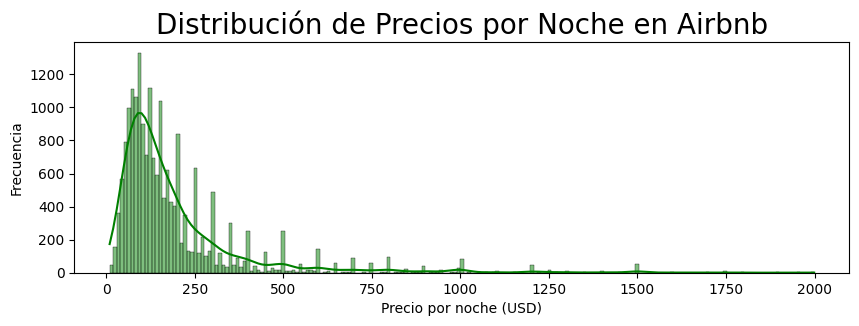

In [11]:
plt.figure(figsize=(10,3))
sns.histplot(eda.price, color="Green", kde=True)
plt.xlabel("Precio por noche (USD)")
plt.ylabel("Frecuencia")
plt.title('Distribución de Precios por Noche en Airbnb',size = 20)
plt.show()

##### Como se observa en el histograma, la distribución del precio está fuertemente sesgada hacia la derecha. La inmensa mayoría de las propiedades se concentra por debajo de los \$250, mientras que existe una larga cola formada por valores que parecen ser outliers hasta alcanzar los 1999. Este sesgo confirma que será necesario aplicar un filtro de valores extremos antes de entrenar los modelos.

##### **Precio en escala logarítmica**
Como la distribución está sesgada, graficamos también el logaritmo del precio.

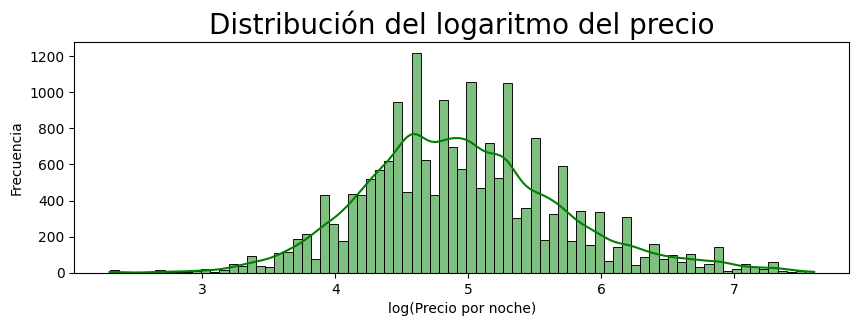

In [12]:
plt.figure(figsize=(10,3))
sns.histplot(np.log(eda.price), color="Green", kde=True)
plt.xlabel("log(Precio por noche)")
plt.ylabel("Frecuencia")
plt.title('Distribución del logaritmo del precio',size = 20)
plt.show()

##### Al aplicar el logaritmo la distribución se vuelve mucho más simétrica, con una forma más parecida a una campana. Por este motivo, en la etapa de modelado se va a predecir **log(precio)** y luego se vuelve a dólares con la función exponencial.

##### **Pairplot para ver la correlación de los precios con las otras variables**

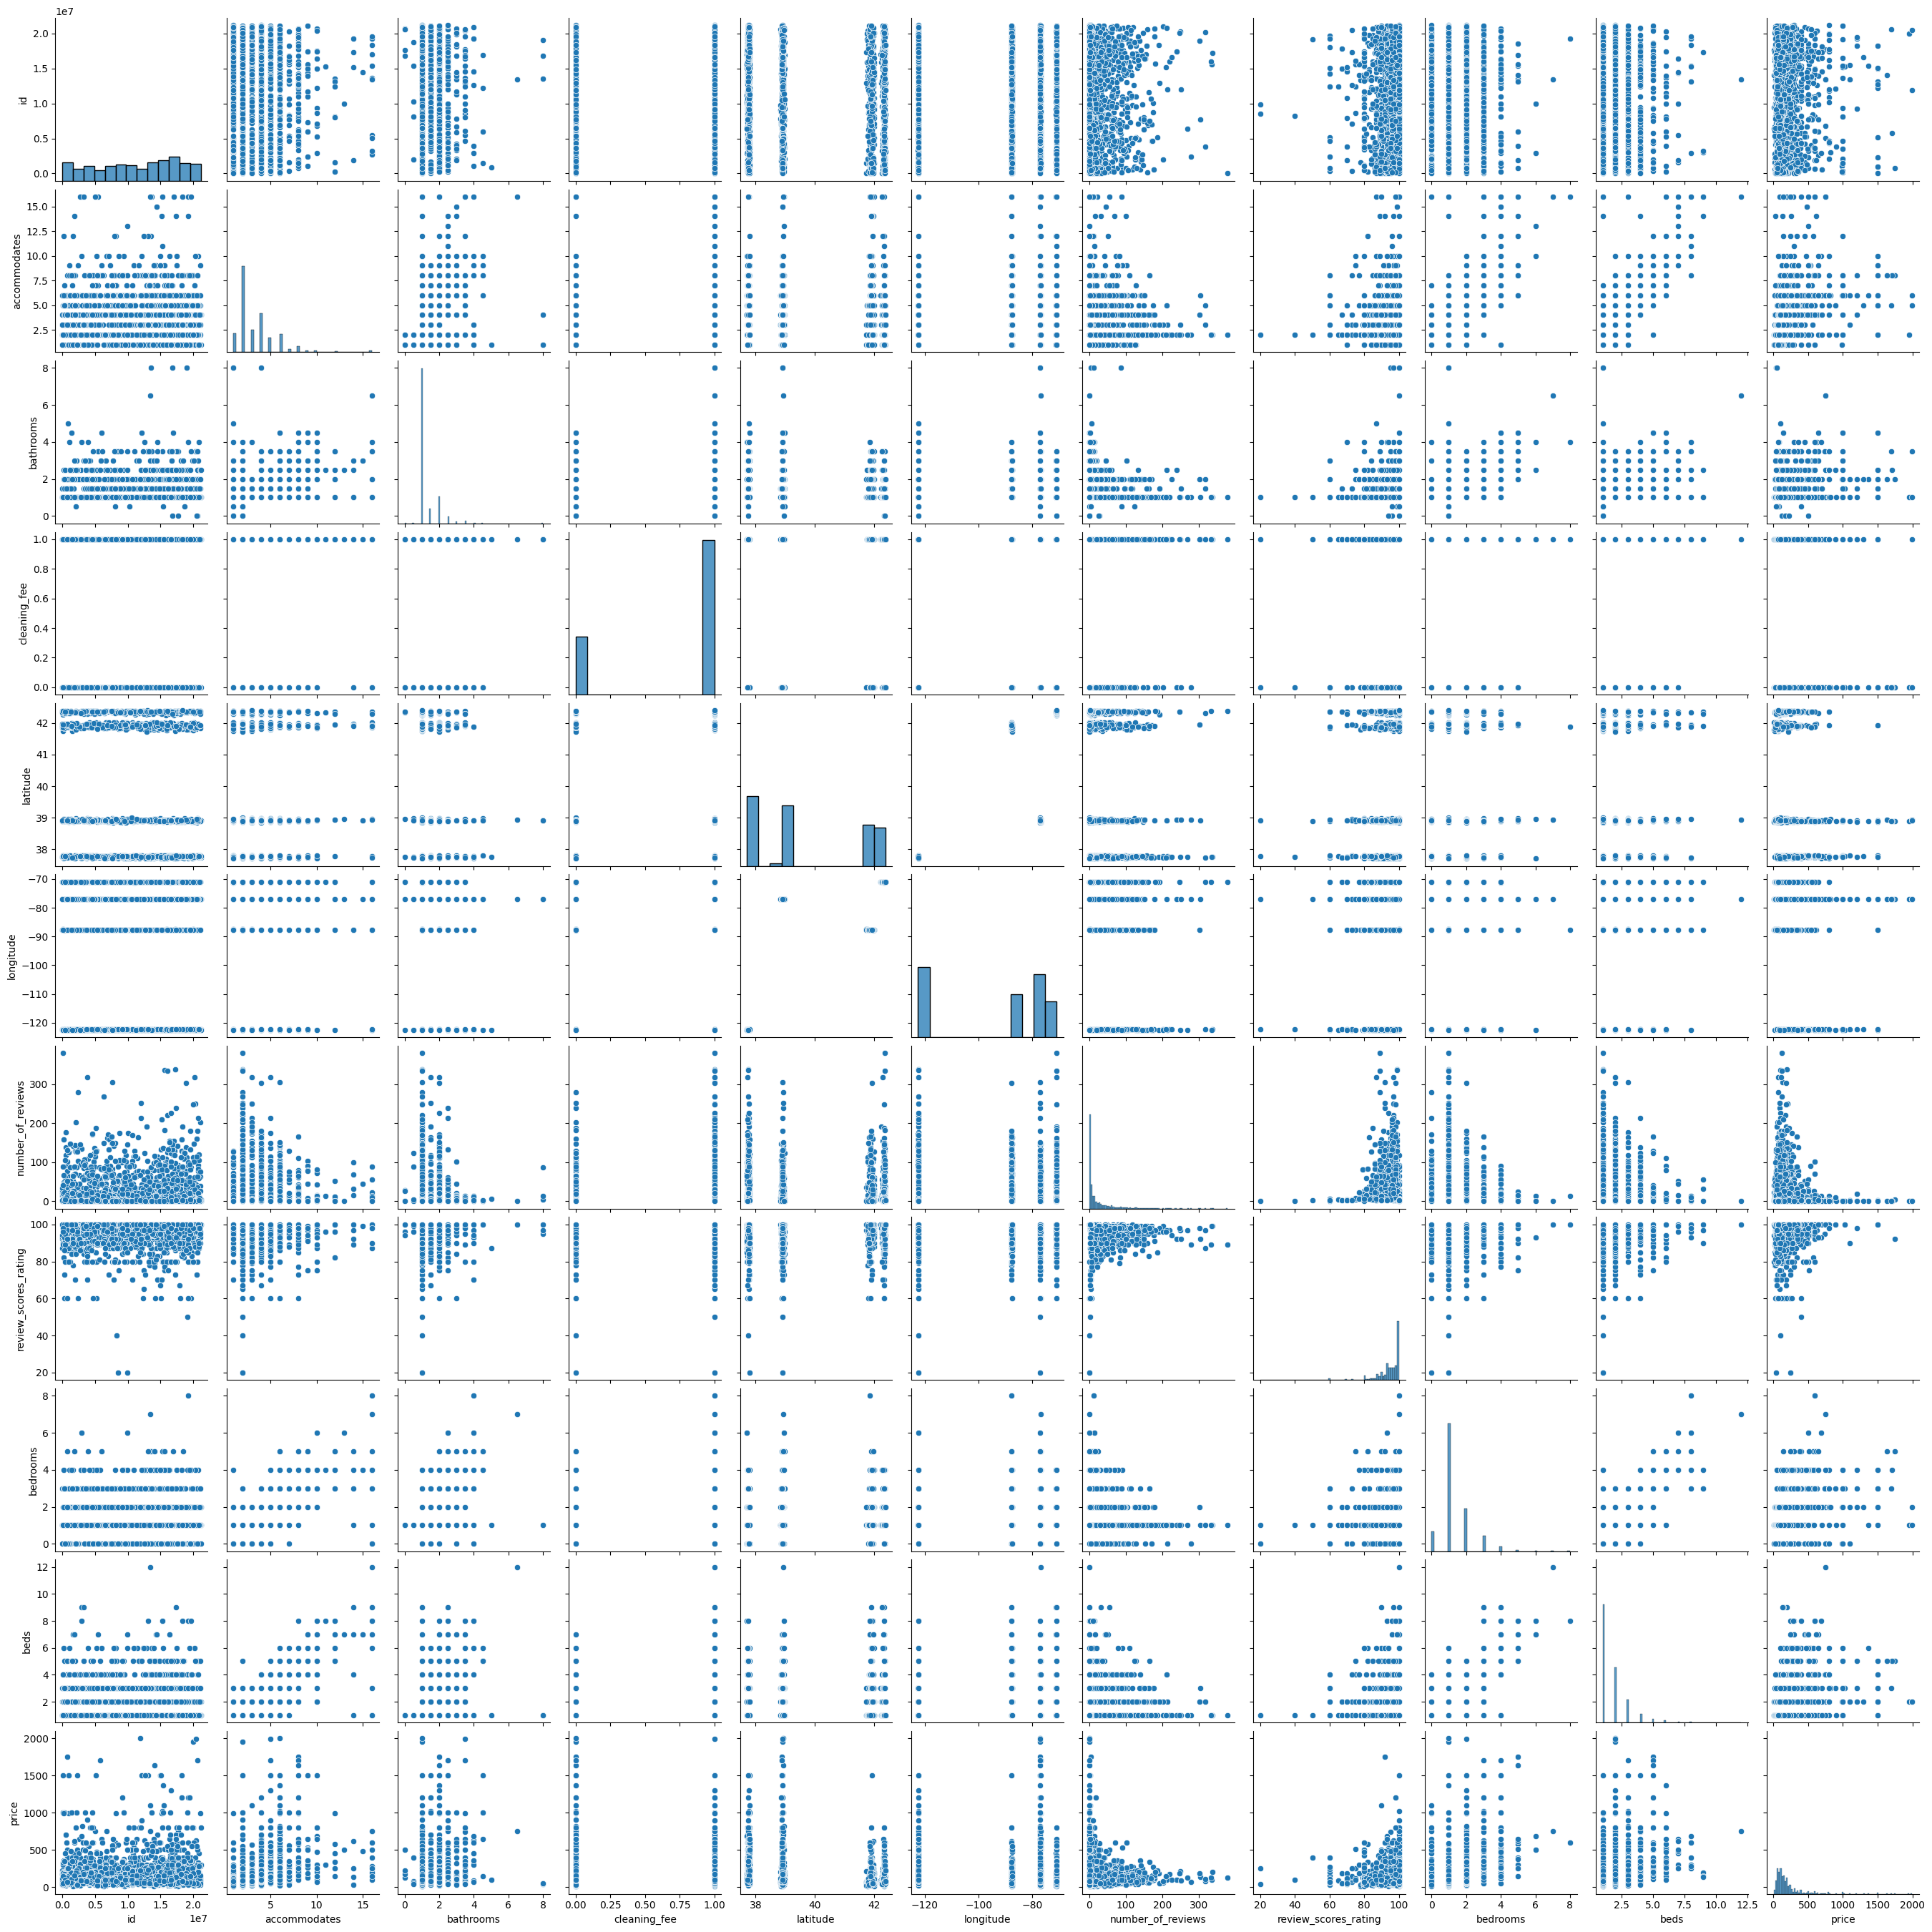

In [13]:
sns.pairplot(eda.sample(2000, random_state=42))
plt.show()

#### El tener 29 variables genera que el pairploting se sature un poco a la vista. Sin embargo, de aqui podemos sacar las siguientes conclusiones:
- Correlación lógica en la capacidad (accommodates, bedrooms, beds): viendo los cruces entre estas variables, se ve una clara tendencia lineal positiva. Es totalmente lógico y esperado, ya que, a mayor cantidad de habitaciones, aumentan proporcionalmente las camas y la cantidad de huéspedes que puede alojar.

- Latitud y longitud: En los gráficos que involucran estas variables se forman "líneas" o agrupaciones de puntos muy definidas. Esto ocurre porque el dataset agrupa varias ciudades distintas de Estados Unidos, por lo que cada clúster corresponde a una ciudad diferente con coordenadas específicas.

- Asimetría en las reseñas (number_of_reviews): En los gráficos donde interviene la cantidad de reviews, la gran mayoría de los puntos se acumulan en la parte inferior (valores cercanos a 0). Esto indica que una enorme porción de las publicaciones tienen pocas opiniones registradas (lo que suele pasar con propiedades nuevas o poco alquiladas).

- La variable id no sirve para predecir: Como era de esperar, los puntos de id están distribuidos de forma totalmente aleatoria y uniforme contra todas las demás variables, por lo que debe eliminarse antes de entrenar cualquier modelo.

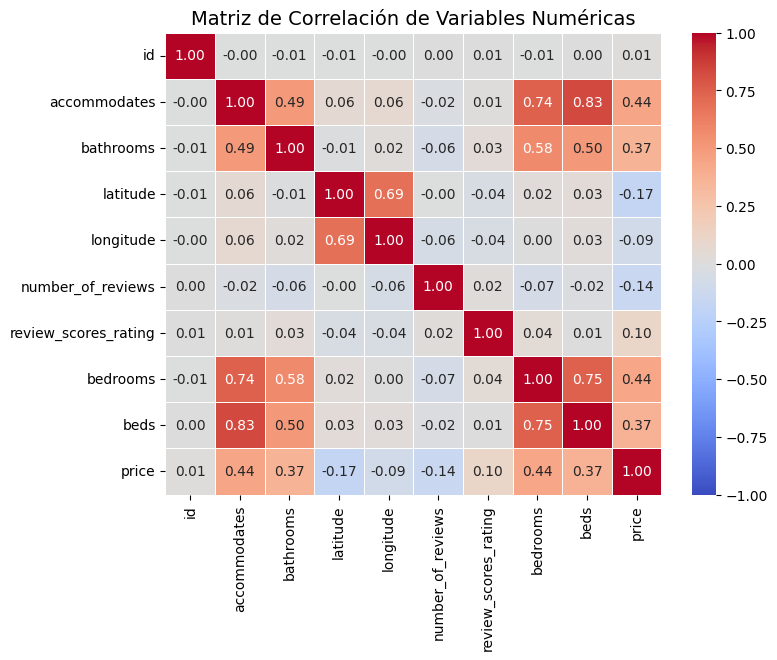

In [14]:
eda_numericas = eda.select_dtypes(include=['float64', 'int64'])

matriz_corr = eda_numericas.corr()
plt.figure(figsize=(8,6))
sns.heatmap(matriz_corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, vmin=-1, vmax=1)

plt.title('Matriz de Correlación de Variables Numéricas', fontsize=14)
plt.show()

#### Mirando los números del gráfico, podemos determinar cuales son los principales impulsores del precio:
- Las variables numéricas que presentan una correlación positiva más alta con el precio por noche son accommodates y bedrooms, seguidas de cerca por beds  y bathrooms. Esto tiene total sentido, ya que nos indica que las propiedades con mayor capacidad de huéspedes, más habitaciones, camas y baños son las que encarecen los precios.

- Fuerte colinealidad: Se observa una correlación muy elevada entre las variables de tamaño y capacidad de la propiedad. Por ejemplo, beds y accommodates marcan un 0.83, bedrooms y beds un 0.75, y bedrooms con accommodates un 0.74.

- Variables sin correlación lineal directa: como ya se menciono, el id muestra una correlación de 0.01 con el precio, por lo que debe ser eliminado.

-  Las coordenadas geográficas (latitud y longitud) muestran valores bajos de correlación lineal con el precio (-0.17 y -0.09), lo que refuerza el hecho de que al mezclar ciudades distintas, una latitud aislada no te dice si es caro o barato (a menos que se cruce de forma espacial).

#### Detección de Valores Atípicos (Outliers)

Generamos diagramas boxplots para la variable objetivo (el precio), comparada según el tipo de habitación.

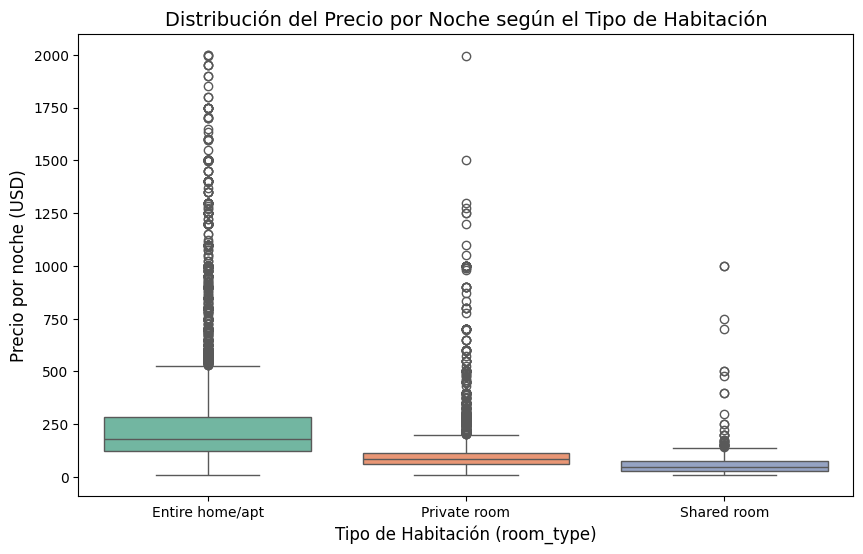

In [15]:
plt.figure(figsize=(10, 6))
sns.boxplot(x='room_type', y='price', data=eda, hue='room_type', palette='Set2', legend=False)

plt.title('Distribución del Precio por Noche según el Tipo de Habitación', fontsize=14)
plt.xlabel('Tipo de Habitación (room_type)', fontsize=12)
plt.ylabel('Precio por noche (USD)', fontsize=12)
plt.show()

##### Análisis de precios según el tipo de alojamiento
El boxplot sobre estos datos permite visualizar la diferencia entre las categorías y la presencia de una importante cantidad de outliers superiores, los cuales se extienden hasta los USD 2000. Se observa que las propiedades de tipo Entire home/apt concentran una mediana sensiblemente mayor (ubicada cerca de los USD 180) y un rango intercuartílico mucho más amplio que las habitaciones privadas (Private room) y compartidas (Shared room). Esta alta dispersión y la presencia de extremos refuerzan la necesidad de aplicar un tratamiento de filtrado de valores atípicos en la posterior etapa de preprocesamiento de datos.

##### **Precio según la ciudad**
Como el dataset reúne varias ciudades de USA, analizamos cómo cambia el precio entre ellas.

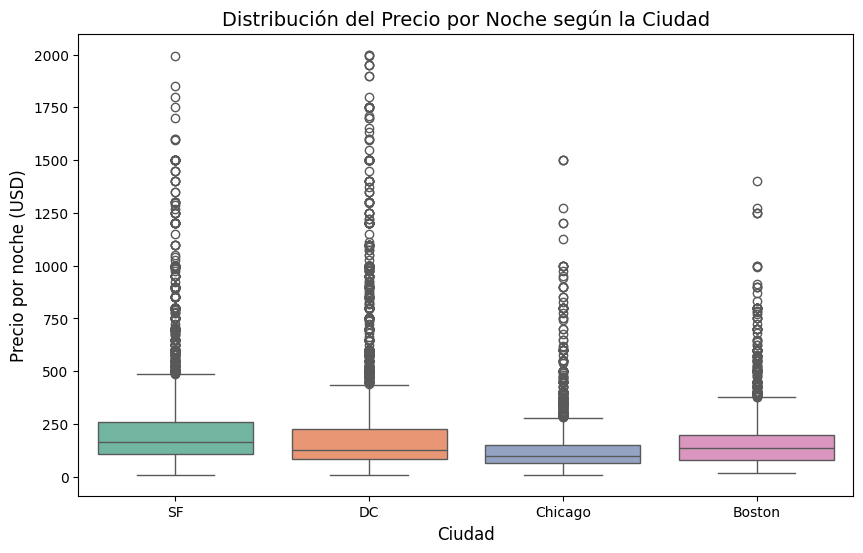

city
Chicago     99.0
DC         125.0
Boston     136.0
SF         165.0
Name: price, dtype: float64


In [16]:
plt.figure(figsize=(10, 6))
sns.boxplot(x='city', y='price', data=eda, hue='city', palette='Set2', legend=False)
plt.title('Distribución del Precio por Noche según la Ciudad', fontsize=14)
plt.xlabel('Ciudad', fontsize=12)
plt.ylabel('Precio por noche (USD)', fontsize=12)
plt.show()

print(eda.groupby('city')['price'].median().sort_values())

##### Se observan diferencias en la mediana y en la dispersión del precio entre ciudades, por lo que `city` va a ser una variable relevante para el modelo.

#### **Conclusiones del EDA y decisiones de preprocesamiento**

Con lo observado en este análisis, en la notebook de Machine Learning se aplican las siguientes decisiones:

- **Variables descartadas:** `id`, `name`, `thumbnail_url` y `description` (identificadores o texto libre sin valor predictivo directo). `first_review` y `last_review` (alrededor de 20% de nulos y su información es similar a `number_of_reviews`). `neighbourhood` y `zipcode` (muchas categorías y valores faltantes; la ubicación ya queda representada por `city`, `latitude` y `longitude`).
- **Variables transformadas:** `host_response_rate` pasa de texto con "%" a número. `amenities` se resume en la cantidad de amenities (`num_amenities`). `host_since` se convierte en la antigüedad del host en días.
- **Datos anómalos:** los valores 0 en `bathrooms` y `beds` se tratan como datos faltantes.
- **Valores faltantes:** se imputan con la mediana (variables numéricas) y con el valor más frecuente (variables categóricas).
- **Outliers del precio:** se filtran los valores por fuera de los percentiles 1 y 99.
- **Variable objetivo:** se predice `log(precio)`, ya que el precio tiene una distribución muy asimétrica.
- **Variables numéricas:** se escalan con `StandardScaler`; las categóricas se codifican con one-hot. Esto se hace dentro de un `Pipeline` para evitar fuga de información (data leakage) entre train y test.
- **Colinealidad:** `accommodates`, `bedrooms` y `beds` están muy correlacionadas entre sí, lo que justifica probar modelos con regularización (Ridge y Lasso) y reducción de dimensionalidad (PCA).